## 4.1 Calibración y rectificación estéreo

Se depuran los pares del checkerboard y se refinan R/T con 12 vistas del ChArUco. Los PKL originales se conservan.

In [1]:
from pathlib import Path
import cv2
import numpy as np
from src.calibration import calibrate_stereo, refine_stereo, load_pair, rectify_pair
from src.visualization import (
    show_rectification, show_disparity, show_cloud, show_camera_poses
)
from src.disparity import compute_disparity
from src.reconstruction import compute_local_cloud, transform_cloud_to_world
from src.pose import estimate_camera_pose
from src.pipeline import process_dataset


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
DATA = Path("data_propia")

CHECKERBOARD_PATTERN = (9, 6)  # Esquinas internas del tablero simple
CHECKERBOARD_SQUARE_MM = 28.0
CALIBRATION_EXCLUDED = (5, 22, 26, 27, 31, 32, 35, 38)  # Pares con alto error estereo
STEREO_REFERENCE_PAIRS = tuple(range(0, 72, 6))  # 12 vistas; validar con el resto

CHARUCO = {
    "squares": (9, 13),
    "square_mm": 42.0,
    "marker_mm": 31.5,
    "dictionary": cv2.aruco.DICT_5X5_100,
}
charuco_dictionary = cv2.aruco.getPredefinedDictionary(CHARUCO["dictionary"])
charuco_board = cv2.aruco.CharucoBoard(
    CHARUCO["squares"], CHARUCO["square_mm"], CHARUCO["marker_mm"], charuco_dictionary
)

MAX_POSE_RMS = 5.0  # Limite de aceptacion de una pose, en pixeles

In [3]:
calibration, maps = calibrate_stereo(
    DATA / "calib", CHECKERBOARD_PATTERN, CHECKERBOARD_SQUARE_MM, CALIBRATION_EXCLUDED
)
calibration, maps = refine_stereo(
    DATA / "captures", calibration, charuco_board, STEREO_REFERENCE_PAIRS
)

In [4]:
np.set_printoptions(precision=4, suppress=True)
for key in ["image_size", "left_K", "left_dist", "right_K", "right_dist", "R", "T"]:
    print(f"{key}:\n{calibration[key]}\n")


image_size:
(1920, 1080)

left_K:
[[600.9715   0.     961.8112]
 [  0.     598.7894 532.4258]
 [  0.       0.       1.    ]]

left_dist:
[[ 0.0077 -0.0258  0.0004 -0.0013  0.0041]]

right_K:
[[603.3662   0.     956.0509]
 [  0.     601.4983 539.4819]
 [  0.       0.       1.    ]]

right_dist:
[[ 0.0067 -0.0247  0.0003 -0.0017  0.0039]]

R:
[[ 0.9999 -0.0005  0.011 ]
 [ 0.0005  1.     -0.0006]
 [-0.011   0.0006  0.9999]]

T:
[[-59.2248]
 [ -0.3074]
 [  0.8853]]



In [5]:
print(f"RMS checkerboard inicial: {calibration['checkerboard_rms']:.4f} px ({len(calibration['used_pairs'])} pares)")
print(f"RMS ajuste R/T: {calibration['rms']:.4f} px ({len(calibration['reference_pairs'])} pares ChArUco)")

RMS checkerboard inicial: 0.6422 px (32 pares)
RMS ajuste R/T: 1.4748 px (12 pares ChArUco)


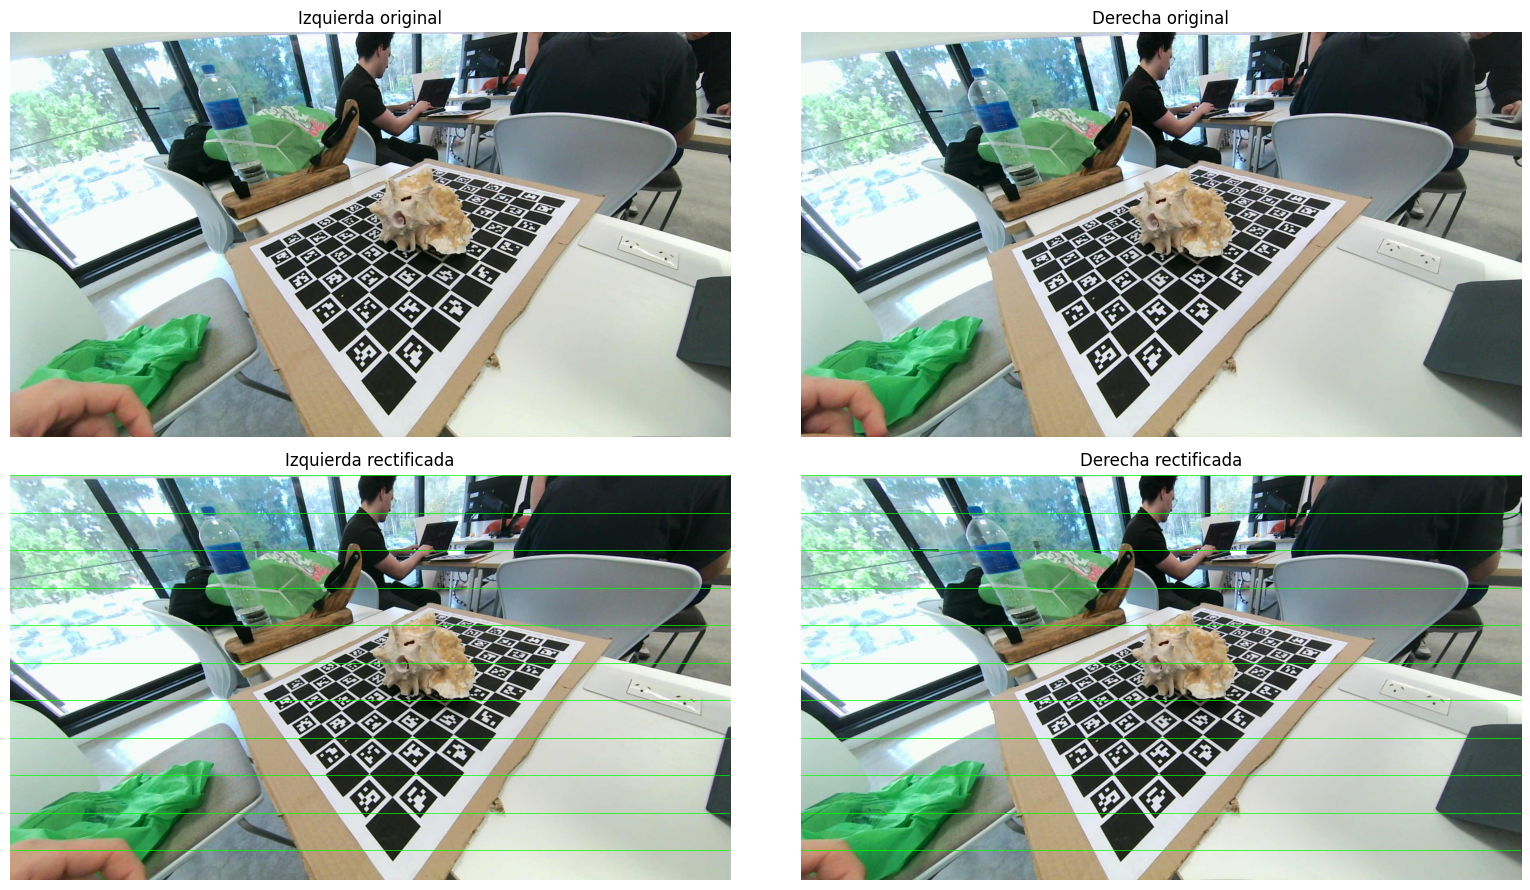

In [6]:
left, right = load_pair(DATA / "captures", 1)
left_rect, right_rect = rectify_pair(left, right, maps)
show_rectification(left, right, left_rect, right_rect)


## 4.2 Disparidad, profundidad y pose de cámaras


In [7]:
disparity = compute_disparity(left_rect, right_rect)

### Nube local


In [8]:
local_cloud = compute_local_cloud(disparity, left_rect, maps["Q"])
local_cloud


PointCloud with 1377993 points.

### Pose global respecto del ChArUco


In [9]:
_, _, camera_pose, pose_rms = estimate_camera_pose(
    left, charuco_board, calibration["left_K"], calibration["left_dist"]
)
print("Pose de la camara izquierda original respecto del tablero:")
print(camera_pose)
print(f"RMS de la pose: {pose_rms:.3f} px")


Pose de la camara izquierda original respecto del tablero:
[[  -0.6563   -0.3741    0.6553  -65.9397]
 [   0.7465   -0.448     0.4919  -40.8511]
 [   0.1095    0.812     0.5733 -271.4202]
 [   0.        0.        0.        1.    ]]
RMS de la pose: 0.827 px


### Transformación de la nube al mundo


In [10]:
world_cloud = transform_cloud_to_world(local_cloud, camera_pose, maps["R1"])


### Visualizaciones sugeridas


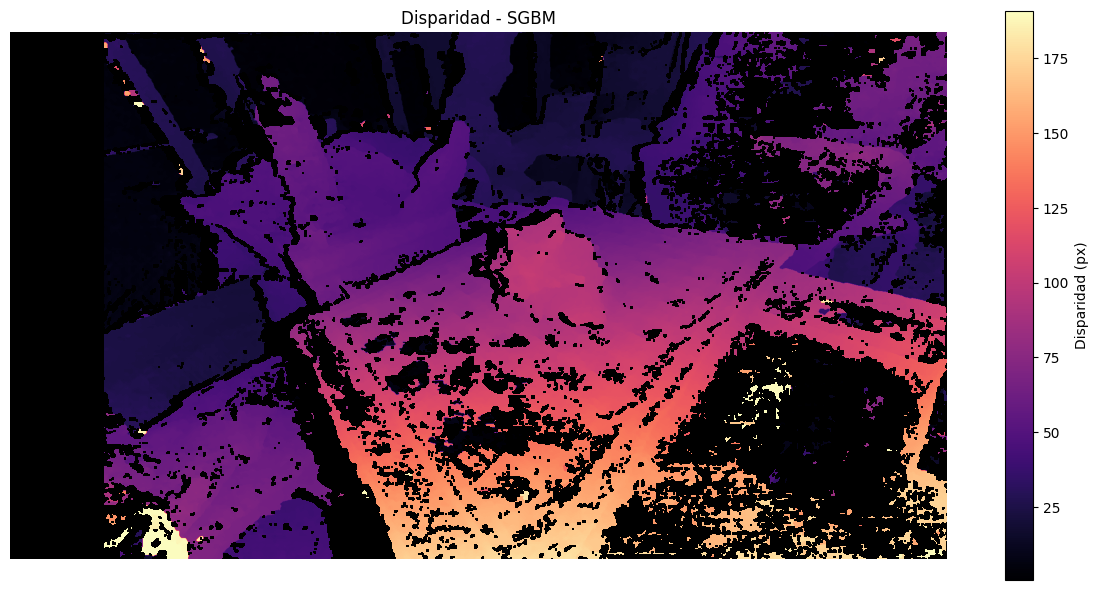

In [11]:
show_disparity(disparity)

In [12]:
show_cloud(local_cloud)

In [13]:
show_cloud(
    world_cloud, camera_pose,
    calibration["left_K"], calibration["image_size"]
)


[Open3D WARNING] GLFW Error: WGL: Failed to make context current: Controlador no válido. 


### Procesamiento de todas las capturas


In [14]:
camera_poses, capture_report = process_dataset(
    DATA, calibration, maps, charuco_board, MAX_POSE_RMS
)
rejected = {number: info["error"] for number, info in capture_report.items() if "error" in info}
print(f"Nubes calculadas: {len(camera_poses)}/{len(capture_report)}")
print("Capturas rechazadas:", rejected)


Revisadas 10 capturas
Revisadas 20 capturas
Revisadas 30 capturas
Revisadas 40 capturas
Revisadas 50 capturas
Revisadas 60 capturas
Revisadas 70 capturas
Revisadas 80 capturas
Nubes calculadas: 77/83
Capturas rechazadas: {33: 'Las esquinas cubren 1.5% de la imagen; se requiere 2.0%', 71: 'Esquinas ChArUco detectadas: 0; minimo requerido: 8', 74: 'Esquinas ChArUco detectadas: 1; minimo requerido: 8', 75: 'Esquinas ChArUco detectadas: 4; minimo requerido: 8', 76: 'Esquinas ChArUco detectadas: 6; minimo requerido: 8', 78: 'Esquinas ChArUco detectadas: 3; minimo requerido: 8'}


In [15]:
show_camera_poses(camera_poses, calibration["left_K"], calibration["image_size"])


[Open3D WARNING] GLFW Error: WGL: Failed to make context current: Controlador no válido. 
